# Colorado River Basin: Hydrologic Accounting, Storage Depletion & Flow Regimes

**Author:** Douglas Schoch • **Course:** DAT1001: Introduction to Data Science (Colorado Mountain College)  
**Sources:** USGS NWIS Water Services, USBR HydroData & RiverOps, USBR Natural Flow (`1906–2024`), USBR Consumptive Uses & Losses (`2000–2024`), Colorado DWR

### Research Question
Under the **1922 Colorado River Compact** and **1944 Mexican Water Treaty**, legal paper apportionments allocate **17.50 MAF/yr** (**18.82 MAF/yr** when including **1.32 MAF/yr** of measured mainstem reservoir evaporation). Because negotiators calibrated those allocations during an unusually wet 1906–1921 period (**18.00 MAF/yr** at Lees Ferry), legal claims exceed modern mainstream inflows (**12.76 MAF/yr** over 2000–2024: **12.40 MAF/yr** at Lees Ferry + **0.36 MAF/yr** from Lower Basin tributaries). This notebook queries live USGS streamflow, inspects the normalized SQLite database (`data/colorado_river_basin.db`), and reproduces the web platform's core analytical figures in Python.

| Project Resource | Live Web Link | Repository Path |
|---|---|---|
| **Interactive Dashboard** | [schochdo.github.io/colorado_river](https://schochdo.github.io/colorado_river/index.html) | [`web/index.html`](../web/index.html) |
| **Data Sources & Provenance** | [Data Sources Registry](https://schochdo.github.io/colorado_river/data_sources.html) | [`web/data_sources.html`](../web/data_sources.html) |
| **AI Prompt & Dialogue Archive** | [AI Prompt Archive](https://schochdo.github.io/colorado_river/ai_complete_prompt_archive.html) | [`web/ai_complete_prompt_archive.html`](../web/ai_complete_prompt_archive.html) |
| **Methodology & Session Logs** | [`AI_LOG.md`](https://github.com/schochdo/CO_River/blob/main/AI_LOG.md) | [`AI_LOG.md`](../AI_LOG.md) • [`CHANGELOG.md`](../CHANGELOG.md) |

### Data Pipeline Summary
- **Immutable Raw Archive (`data/raw/`):** `27` federal workbooks, compacts, and agency downloads verified via SHA-256 in `data/raw/MANIFEST.csv`.
- **Single Source of Truth (`data/colorado_river_basin.db`):** Normalized SQLite store refreshed every 6 hours by GitHub Actions (`.github/workflows/update_data.yml`).
- **Static JSON Export (`scripts/export_sqlite_to_json.py`):** Compiles `10` static JSON files in `web/data/` for GitHub Pages hosting.
- **Browser Fetch Fallback:** Direct CORS-enabled REST queries to USGS NWIS (`waterservices.usgs.gov`), falling back to the 6-hour snapshot (`latest_metrics.json`).
- **Dimensional Rule:** Instantaneous rate $Q$ (`cfs`) and cumulative volume $V$ (`AF`, `MAF`) remain strictly separated: $1\text{ cfs sustained for 1 year} = 723.97\text{ AF} \approx 0.000724\text{ MAF}$.


<!-- RAW_HTML_FLOWCHART -->
<div style="background:#faf8f4;border:1px solid #cfc8ba;border-radius:2px;padding:14px 16px;margin:4px 0 8px 0;">
  <div style="font-size:11px;font-weight:800;text-transform:uppercase;letter-spacing:0.05em;color:#475569;margin-bottom:8px;">Unidirectional Data Pipeline &amp; Two-Tier Browser Delivery</div>
  <svg viewBox="0 0 920 198" width="100%" style="max-width:920px;height:auto;display:block;font-family:'Inter',-apple-system,sans-serif;" role="img" aria-label="Colorado River Data Pipeline Flowchart">
    <defs>
      <marker id="nb-arr" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6" markerHeight="6" orient="auto-start-reverse">
        <path d="M 0 1.5 L 8.5 5 L 0 8.5 z" fill="#475569"/>
      </marker>
      <marker id="nb-arr-blue" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6" markerHeight="6" orient="auto-start-reverse">
        <path d="M 0 1.5 L 8.5 5 L 0 8.5 z" fill="#2b5c8f"/>
      </marker>
    </defs>
    <!-- Stage 1A: Immutable Raw Archive -->
    <rect x="8" y="10" width="198" height="76" rx="2" fill="#ffffff" stroke="#b8ae9c"/>
    <rect x="8" y="10" width="198" height="20" rx="2" fill="#ebe4d6"/>
    <text x="16" y="24" font-size="10" font-weight="800" fill="#0f172a">1A. RAW FEDERAL ARCHIVE</text>
    <text x="16" y="44" font-size="10.5" font-weight="700" fill="#1e293b">data/raw/ (27 Files · 50.3 MB)</text>
    <text x="16" y="59" font-size="9.5" fill="#475569">USBR Natural Flow, CUL, Compacts</text>
    <text x="16" y="73" font-size="9" font-family="monospace" fill="#7c4318">SHA-256 verified in MANIFEST.csv</text>
    <!-- Stage 1B: Scheduled Live Telemetry -->
    <rect x="8" y="106" width="198" height="80" rx="2" fill="#ffffff" stroke="#b8ae9c"/>
    <rect x="8" y="106" width="198" height="20" rx="2" fill="#ebe4d6"/>
    <text x="16" y="120" font-size="10" font-weight="800" fill="#0f172a">1B. 6-HOUR GITHUB ACTIONS</text>
    <text x="16" y="140" font-size="10.5" font-weight="700" fill="#1e293b">USGS · USBR · CDWR REST APIs</text>
    <text x="16" y="155" font-size="9.5" fill="#475569">00:00, 06:00, 12:00, 18:00 UTC</text>
    <text x="16" y="170" font-size="9" font-family="monospace" fill="#2b5c8f">15-min P7D/P30D &amp; EOM storage</text>
    <!-- Arrows 1 -> 2 -->
    <path d="M 206 48 L 242 48 L 242 82 L 266 82" fill="none" stroke="#475569" stroke-width="1.4" marker-end="url(#nb-arr)"/>
    <path d="M 206 146 L 242 146 L 242 112 L 266 112" fill="none" stroke="#475569" stroke-width="1.4" marker-end="url(#nb-arr)"/>
    <!-- Stage 2: SQLite SSOT -->
    <rect x="270" y="42" width="202" height="112" rx="2" fill="#ffffff" stroke="#2b5c8f" stroke-width="1.5"/>
    <rect x="270" y="42" width="202" height="22" rx="2" fill="#2b5c8f"/>
    <text x="279" y="57" font-size="10" font-weight="800" fill="#ffffff">2. SQLITE SINGLE SOURCE OF TRUTH</text>
    <text x="279" y="79" font-size="10.5" font-weight="700" font-family="monospace" fill="#0f172a">colorado_river_basin.db</text>
    <text x="279" y="95" font-size="9.5" fill="#334155">31 normalized tables · 2 SQL views</text>
    <text x="279" y="110" font-size="9.5" fill="#334155">2000–2024 baseline · 1922–2024 POR</text>
    <text x="279" y="125" font-size="9.5" fill="#334155">92 facilities · WY 2016–2025 RBI</text>
    <text x="279" y="142" font-size="9" font-family="monospace" fill="#3f6f58">Gate: scripts/data_smoke_test.py</text>
    <!-- Arrow 2 -> Notebook & Exporter -->
    <path d="M 472 76 L 516 48" fill="none" stroke="#2b5c8f" stroke-width="1.4" marker-end="url(#nb-arr-blue)"/>
    <path d="M 472 118 L 516 142" fill="none" stroke="#475569" stroke-width="1.4" marker-end="url(#nb-arr)"/>
    <!-- Stage 3A: Research Notebook -->
    <rect x="520" y="10" width="176" height="76" rx="2" fill="#ffffff" stroke="#b8ae9c"/>
    <rect x="520" y="10" width="176" height="20" rx="2" fill="#ebe4d6"/>
    <text x="528" y="24" font-size="10" font-weight="800" fill="#0f172a">3A. JUPYTER NOTEBOOK</text>
    <text x="528" y="43" font-size="10" font-weight="700" font-family="monospace" fill="#1e293b">colorado_river_analysis</text>
    <text x="528" y="58" font-size="9.5" fill="#475569">Direct SQLite SQL + Seaborn</text>
    <text x="528" y="73" font-size="9" font-family="monospace" fill="#7c4318">Figures 1–5 (nbclient PNGs)</text>
    <!-- Stage 3B: Static JSON Exporter -->
    <rect x="520" y="106" width="176" height="80" rx="2" fill="#ffffff" stroke="#b8ae9c"/>
    <rect x="520" y="106" width="176" height="20" rx="2" fill="#ebe4d6"/>
    <text x="528" y="120" font-size="10" font-weight="800" fill="#0f172a">3B. STATIC JSON EXPORT</text>
    <text x="528" y="139" font-size="10" font-weight="700" font-family="monospace" fill="#1e293b">export_sqlite_to_json.py</text>
    <text x="528" y="154" font-size="9.5" fill="#475569">10 JSON contracts in web/data/</text>
    <text x="528" y="170" font-size="9" font-family="monospace" fill="#475569">Zero runtime DB server</text>
    <!-- Arrow 3B -> 4 -->
    <path d="M 696 146 L 730 146" fill="none" stroke="#475569" stroke-width="1.4" marker-end="url(#nb-arr)"/>
    <!-- Stage 4: Browser Two-Tier Delivery -->
    <rect x="734" y="10" width="178" height="176" rx="2" fill="#ffffff" stroke="#3f6f58" stroke-width="1.4"/>
    <rect x="734" y="10" width="178" height="20" rx="2" fill="#3f6f58"/>
    <text x="742" y="24" font-size="10" font-weight="800" fill="#ffffff">4. BROWSER CLIENT (CDN)</text>
    <text x="742" y="45" font-size="10" font-weight="700" fill="#0f172a">Tier 1: Live USGS Fetch</text>
    <text x="742" y="59" font-size="9.2" fill="#475569">Direct CORS REST query</text>
    <text x="742" y="72" font-size="8.8" font-family="monospace" fill="#2b5c8f">waterservices.usgs.gov</text>
    <line x1="742" y1="84" x2="904" y2="84" stroke="#dfd9cc" stroke-dasharray="3,2"/>
    <text x="742" y="101" font-size="10" font-weight="700" fill="#0f172a">Tier 2: Snapshot Fallback</text>
    <text x="742" y="115" font-size="9.2" fill="#475569">If offline/timeout, loads 6h</text>
    <text x="742" y="128" font-size="8.8" font-family="monospace" fill="#7c4318">web/data/latest_metrics.json</text>
    <line x1="742" y1="140" x2="904" y2="140" stroke="#dfd9cc"/>
    <text x="742" y="157" font-size="9.5" font-weight="700" fill="#334155">MapLibre · D3 · Chart.js</text>
    <text x="742" y="172" font-size="9" fill="#475569">GitHub Pages Static Edge</text>
  </svg>
</div>


In [1]:
import sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DB_PATH = ROOT / 'data' / 'colorado_river_basin.db'
conn = sqlite3.connect(DB_PATH)

def q(sql):
    return pd.read_sql_query(sql, conn)

PALETTE = {
    'blue': '#2b5c8f', 'ochre': '#c26d2d', 'sage': '#3f6f58',
    'red': '#9e3f32', 'ink': '#0f172a', 'slate': '#475569', 'gold': '#b5892e',
}
sns.set_theme(style='whitegrid', rc={
    'axes.edgecolor': '#cfc8ba', 'axes.facecolor': '#faf8f4',
    'figure.facecolor': '#ffffff', 'grid.color': '#e6e0d5', 'grid.linestyle': ':',
})


## 1. Live Public API Sample: Lee's Ferry (`USGS #09380000`)
**Takeaway:** Lee's Ferry, Arizona (`16` miles below Glen Canyon Dam) is the legal dividing point between the Upper and Lower Basins (`75.0 MAF` rolling 10-year delivery obligation). A single REST call to the USGS Instantaneous Values service retrieves the latest 15-minute discharge (`parameterCd=00060`).


In [2]:
url = 'https://waterservices.usgs.gov/nwis/iv/'
params = {'sites': '09380000', 'parameterCd': '00060', 'format': 'json'}
try:
    resp = requests.get(url, params=params, timeout=10)
    resp.raise_for_status()
    obs = resp.json()['value']['timeSeries'][0]['values'][0]['value'][-1]
    print(f"Lee's Ferry (#09380000): {float(obs['value']):,.0f} cfs at {obs['dateTime']} (USGS NWIS IV)")
except Exception as exc:
    print(f'Live USGS request unavailable ({exc}) — see web/data/latest_metrics.json')


Lee's Ferry (#09380000): 8,350 cfs at 2026-11-26T20:00:00.000-07:00 (USGS NWIS IV)


## 2. Core SQLite Tables & Standardized Date Windows
**Takeaway:** All figures below read directly from six tables in `data/colorado_river_basin.db` using a standardized temporal hierarchy:
1. **Unified Contemporary Baseline (`2000–2024`, 25 Years):** Used across all modern water-budget, Compact deficit, schematic, and seasonal Powell inflow/release views. Starting in `2000` captures the full Millennium Drought from when the five major reservoirs were nearly full (`51.80 MAF` on `Dec 31, 1999`), and ending in `2024` reflects the 1–2 year federal verification lag on post-season USBR Natural Flow and Consumptive Uses & Losses (CUL) workbooks (whereas live streamgages and reservoir elevations run through **November 2026**).
2. **Full Historical Context (`1922–2024` & `1937–2026`):** Long-term timeline charts show the complete 103-year post-Compact natural flow record and 90-year federal reservoir trajectory.
3. **Active Streamgage Regime Diagnostics (`WY 2016–2025` & `WY 2021`):** Daily Richards–Baker Flashiness (`RBI`) uses the most recent 10 complete water years across active USGS streamgages, paired with the `WY 2021` flash-flood vs. snowmelt case study.


In [3]:
core_tables = [
    'annual_lees_ferry', 'basin_storage_timeline', 'seasonal_supply_demand',
    'tributary_summaries', 'event_hydrograph_comparison', 'water_budget_nodes',
]
tbl_counts = [{'table': t, 'rows': conn.execute(f'SELECT COUNT(*) FROM {t}').fetchone()[0]} for t in core_tables]
print('SQLite Tables Used in This Notebook:')
print(pd.DataFrame(tbl_counts).to_string(index=False))

eras = q('''
    SELECT '1906–1921 (Pre-Compact Pluvial)' AS window, COUNT(*) AS water_years, ROUND(AVG(natural_flow_maf), 2) AS mean_natural_maf FROM annual_lees_ferry WHERE water_year BETWEEN 1906 AND 1921
    UNION ALL SELECT '1906–2024 (Full USBR Record)', COUNT(*), ROUND(AVG(natural_flow_maf), 2) FROM annual_lees_ferry WHERE water_year BETWEEN 1906 AND 2024
    UNION ALL SELECT '1922–2024 (Post-Compact Era)', COUNT(*), ROUND(AVG(natural_flow_maf), 2) FROM annual_lees_ferry WHERE water_year BETWEEN 1922 AND 2024
    UNION ALL SELECT '2000–2024 (Millennium Drought Baseline)', COUNT(*), ROUND(AVG(natural_flow_maf), 2) FROM annual_lees_ferry WHERE water_year BETWEEN 2000 AND 2024
''')
print('\nUSBR Lees Ferry Natural Flow Windows:')
print(eras.to_string(index=False))


SQLite Tables Used in This Notebook:
                      table  rows
          annual_lees_ferry   119
     basin_storage_timeline    90
     seasonal_supply_demand   365
        tributary_summaries     6
event_hydrograph_comparison   365
         water_budget_nodes    25

USBR Lees Ferry Natural Flow Windows:
                                 window  water_years  mean_natural_maf
        1906–1921 (Pre-Compact Pluvial)           16             18.00
           1906–2024 (Full USBR Record)          119             14.63
           1922–2024 (Post-Compact Era)          103             14.11
2000–2024 (Millennium Drought Baseline)           25             12.40


## 3. Compact Promises vs. Physical Natural Flow (`Water Years 1922–2024`)
**Takeaway:** Across `103` Compact water years, unimpaired natural flow at Lees Ferry fell short of the `16.50 MAF/yr` core target (`15.00` domestic Art. III.a + `1.50` Mexico Treaty) in **70 of 103 years (68.0%)**—and **21 of 25 years** since 2000. After Glen Canyon Dam closed in `1963`, gaged Lees Ferry releases flatten near `8.2–9.5 MAF/yr` while upstream consumptive use (~`3.9–4.4 MAF/yr`) and reservoir storage absorb annual swings.


Years below 16.50 MAF: 70/103 (68.0%) overall; 21/25 since WY 2000.


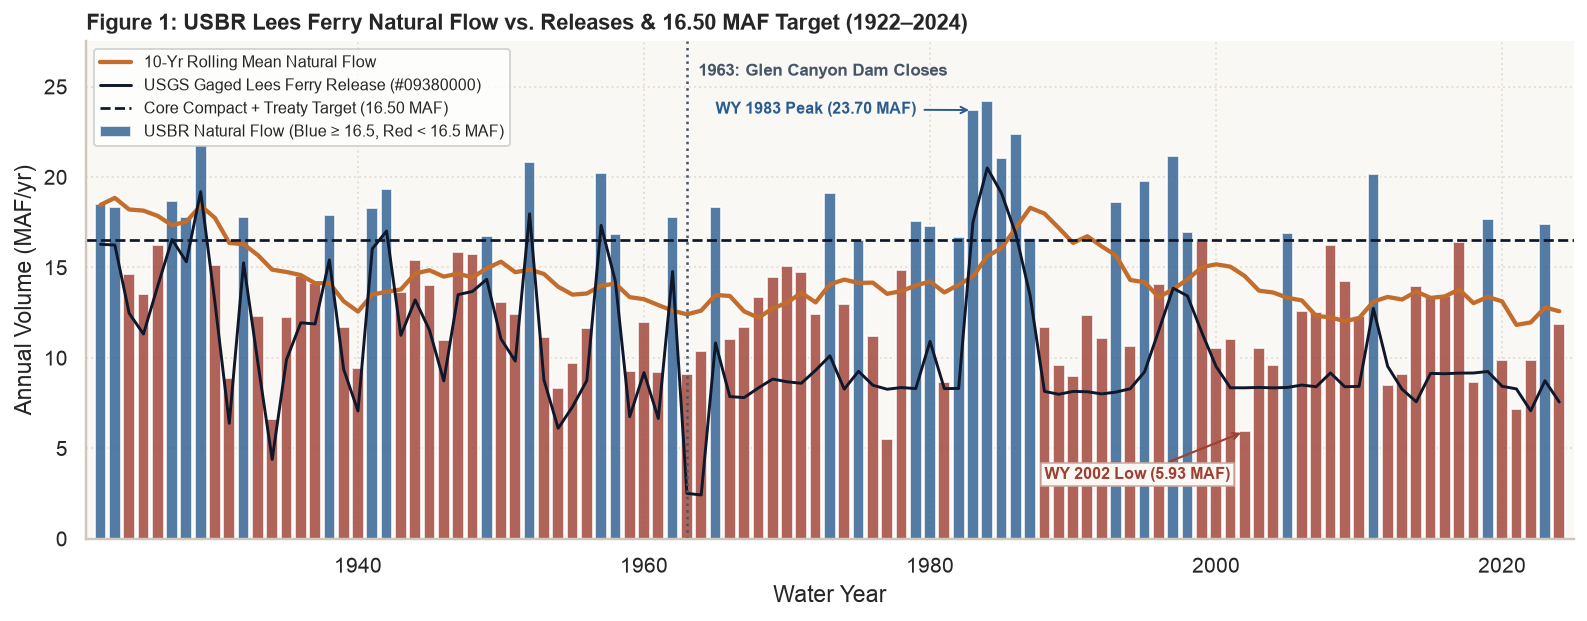

In [4]:
df_lf = q('SELECT * FROM view_compact_surplus_deficit ORDER BY water_year')
deficit_all = int((df_lf['natural_flow_maf'] < 16.5).sum())
deficit_2000 = int((df_lf.loc[df_lf['water_year'] >= 2000, 'natural_flow_maf'] < 16.5).sum())
print(f'Years below 16.50 MAF: {deficit_all}/{len(df_lf)} ({100*deficit_all/len(df_lf):.1f}%) overall; {deficit_2000}/25 since WY 2000.')

fig, ax = plt.subplots(figsize=(11.5, 4.6), dpi=140)
colors = [PALETTE['blue'] if v >= 16.5 else PALETTE['red'] for v in df_lf['natural_flow_maf']]
ax.bar(df_lf['water_year'], df_lf['natural_flow_maf'], color=colors, alpha=0.80, width=0.82, label='USBR Natural Flow (Blue ≥ 16.5, Red < 16.5 MAF)')
sns.lineplot(data=df_lf, x='water_year', y='ten_year_rolling_mean_maf', ax=ax, color=PALETTE['ochre'], lw=2.2, label='10-Yr Rolling Mean Natural Flow')
sns.lineplot(data=df_lf, x='water_year', y='gaged_flow_maf', ax=ax, color=PALETTE['ink'], lw=1.5, label='USGS Gaged Lees Ferry Release (#09380000)')
ax.axhline(16.5, color=PALETTE['ink'], ls='--', lw=1.4, label='Core Compact + Treaty Target (16.50 MAF)')
ax.axvline(1963, color=PALETTE['slate'], ls=':', lw=1.3)
ax.text(1963.8, 25.6, '1963: Glen Canyon Dam Closes', fontsize=8.5, color=PALETTE['slate'], fontweight='bold')
ax.annotate('WY 1983 Peak (23.70 MAF)', xy=(1983, 23.70), xytext=(1965, 23.5),
            arrowprops=dict(arrowstyle='->', color=PALETTE['blue'], lw=1.0), fontsize=8.2, fontweight='bold', color=PALETTE['blue'])
ax.annotate('WY 2002 Low (5.93 MAF)', xy=(2002, 5.93), xytext=(1988, 3.3),
            bbox=dict(boxstyle='square,pad=0.22', fc='#faf8f4', ec='#cfa9a2', lw=0.8),
            arrowprops=dict(arrowstyle='->', color=PALETTE['red'], lw=1.1), fontsize=8.2, fontweight='bold', color=PALETTE['red'])
ax.set_title('Figure 1: USBR Lees Ferry Natural Flow vs. Releases & 16.50 MAF Target (1922–2024)', fontsize=11.5, fontweight='bold', loc='left')
ax.set_xlabel('Water Year')
ax.set_ylabel('Annual Volume (MAF/yr)')
ax.set_xlim(1921, 2025)
ax.set_ylim(0, 27.5)
ax.legend(loc='upper left', fontsize=8, frameon=True, facecolor='white')
sns.despine(ax=ax)
plt.tight_layout()
plt.show()


## 4. Multi-Decade Storage Drawdown (`1937–2026`) & Seasonal Inflow Pulse (`WY 2000–2024`)
**Takeaway:**
- **Figure 2:** Five major federal reservoirs (Lake Mead, Lake Powell, Flaming Gorge, Navajo, Blue Mesa) buffered structural deficits after 1999—falling **29.8 MAF** net across the `2000–2024` accounting window (`51.8 MAF` on `Dec 31, 1999` to `22.0 MAF` on `Dec 31, 2024`), reaching a **37.2 MAF** peak-to-trough low (`53.5 MAF` `Sep 1999` to `16.3 MAF` `Mar 2023`) before the wet 2023 snowpack rebound, and standing at **17.64 MAF** in `Nov 2026`.
- **Figure 3:** Comparing 25-year daily averages (`Water Years 2000–2024`: `Oct 1, 1999 – Sep 30, 2024`) of gaged Lake Powell inflows (`Cisco + Green River + San Juan`) against Glen Canyon Dam releases (`Lees Ferry #09380000`) shows an **88-day** snowmelt refill pulse (`37,297 cfs` peak) supporting **277 days** of net reservoir drawdown (`12,040 cfs` = `8.72 MAF/yr` mean release).


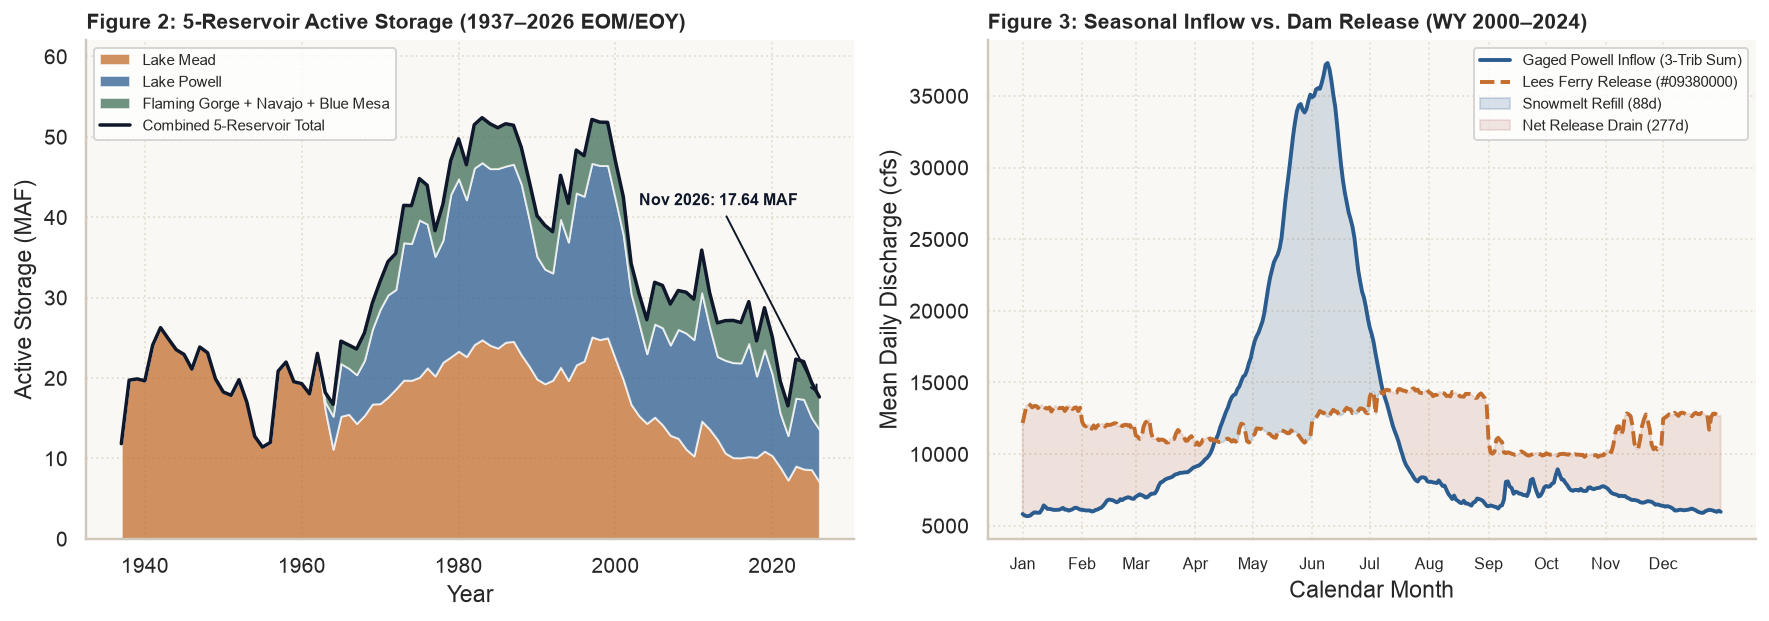

In [5]:
df_stor = q('SELECT * FROM basin_storage_timeline ORDER BY year')
df_stor['upper_crsp_maf'] = df_stor['flaming_gorge_maf'] + df_stor['navajo_maf'] + df_stor['blue_mesa_maf']
df_sd = q('SELECT * FROM seasonal_supply_demand ORDER BY doy')
s_meta = dict(q('SELECT meta_key, meta_value FROM seasonal_meta').values)

fig, (ax2, ax3) = plt.subplots(1, 2, figsize=(12.8, 4.6), dpi=140)

ax2.stackplot(df_stor['year'], df_stor['mead_maf'], df_stor['powell_maf'], df_stor['upper_crsp_maf'],
              labels=['Lake Mead', 'Lake Powell', 'Flaming Gorge + Navajo + Blue Mesa'],
              colors=[PALETTE['ochre'], PALETTE['blue'], PALETTE['sage']], alpha=0.75)
sns.lineplot(data=df_stor, x='year', y='total_major_storage_maf', ax=ax2, color=PALETTE['ink'], lw=1.8, label='Combined 5-Reservoir Total')
latest_yr, latest_tot = int(df_stor.iloc[-1]['year']), float(df_stor.iloc[-1]['total_major_storage_maf'])
ax2.annotate(f'Nov {latest_yr}: {latest_tot:.2f} MAF', xy=(latest_yr, latest_tot), xytext=(2003, 41.5),
             arrowprops=dict(arrowstyle='->', color=PALETTE['ink'], lw=1.0), fontsize=8.2, fontweight='bold', color=PALETTE['ink'])
ax2.set_title('Figure 2: 5-Reservoir Active Storage (1937–2026 EOM/EOY)', fontsize=10.8, fontweight='bold', loc='left')
ax2.set_xlabel('Year')
ax2.set_ylabel('Active Storage (MAF)')
ax2.set_ylim(0, 62)
ax2.legend(loc='upper left', fontsize=7.8, frameon=True, facecolor='white')
sns.despine(ax=ax2)

sns.lineplot(data=df_sd, x='doy', y='supply_cfs', ax=ax3, color=PALETTE['blue'], lw=2.0, label='Gaged Powell Inflow (3-Trib Sum)')
sns.lineplot(data=df_sd, x='doy', y='demand_cfs', ax=ax3, color=PALETTE['ochre'], ls='--', lw=2.0, label='Lees Ferry Release (#09380000)')
ax3.fill_between(df_sd['doy'], df_sd['supply_cfs'], df_sd['demand_cfs'],
                 where=(df_sd['supply_cfs'] >= df_sd['demand_cfs']), color=PALETTE['blue'], alpha=0.18,
                 label=f"Snowmelt Refill ({s_meta['surplus_days']}d)")
ax3.fill_between(df_sd['doy'], df_sd['supply_cfs'], df_sd['demand_cfs'],
                 where=(df_sd['supply_cfs'] < df_sd['demand_cfs']), color=PALETTE['red'], alpha=0.13,
                 label=f"Net Release Drain ({s_meta['deficit_days']}d)")
ax3.set_xticks([1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335])
ax3.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], fontsize=8.2)
ax3.set_title('Figure 3: Seasonal Inflow vs. Dam Release (WY 2000–2024)', fontsize=10.8, fontweight='bold', loc='left')
ax3.set_xlabel('Calendar Month')
ax3.set_ylabel('Mean Daily Discharge (cfs)')
ax3.legend(loc='upper right', fontsize=7.8, frameon=True, facecolor='white')
sns.despine(ax=ax3)
plt.tight_layout()
plt.show()


## 5. Tributary Flashiness (`RBI`) vs. Volume & The `WY 2021` Flash-Flood Case Study
**Takeaway:**
- **Figure 4A:** Across 10 years of daily USGS discharge (`Water Years 2016–2025`), snowmelt tributaries (`Cisco`, `Green River`, `San Juan`) have moderate flashiness (`RBI 0.05–0.11`) and supply **99.2%** of gaged Lake Powell inflow, whereas flashy desert channels (`Dirty Devil`, `Escalante`, `RBI >= 0.15`) contribute **0.78%**.
- **Figure 4B (Rate vs. Volume):** In `Water Year 2021`, a September flash flood on the `Dirty Devil` peaked at **7,320 cfs**—nearly matching `Cisco`'s **8,300 cfs** snowmelt peak—yet carried **16,171 AF** over 3 days (**79,047 AF** for the entire water year, `+3.06 inches` on Lake Powell) versus **2.07 MAF** at `Cisco` (**~26×** more water-year volume from a similar peak).


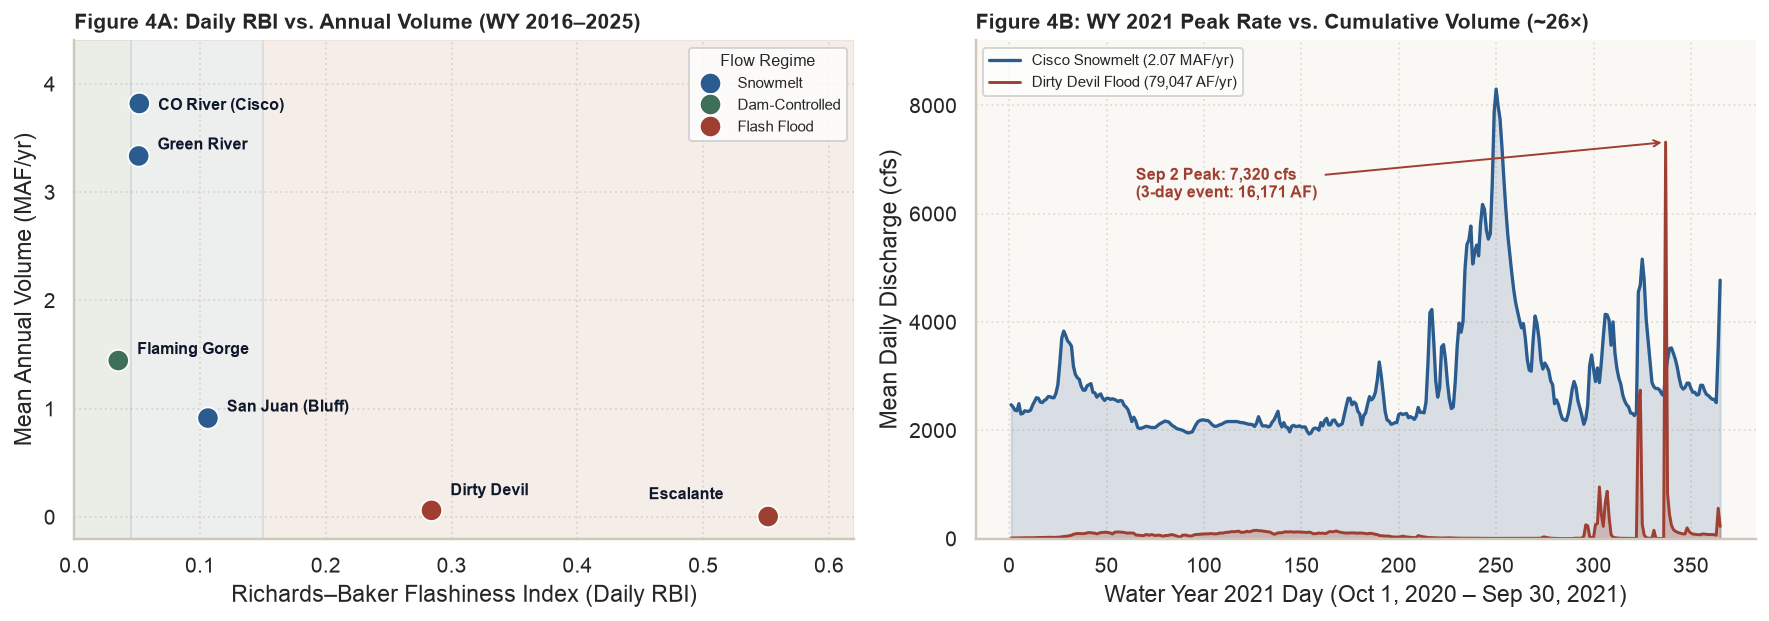

In [6]:
df_trib = q('SELECT * FROM tributary_summaries ORDER BY annual_maf DESC')
df_ev = q('SELECT * FROM event_hydrograph_comparison ORDER BY obs_date')
ev_meta = dict(q('SELECT meta_key, meta_value FROM event_hydrograph_meta').values)
df_ev['wy_day'] = range(1, len(df_ev) + 1)

fig, (ax4a, ax4b) = plt.subplots(1, 2, figsize=(12.8, 4.6), dpi=140)

ax4a.axvspan(0.0, 0.045, color=PALETTE['sage'], alpha=0.08)
ax4a.axvspan(0.045, 0.150, color=PALETTE['blue'], alpha=0.06)
ax4a.axvspan(0.150, 0.62, color=PALETTE['red'], alpha=0.06)
reg_names = {'snowmelt': 'Snowmelt', 'dam_controlled': 'Dam-Controlled', 'flash_flood': 'Flash Flood'}
df_trib['Regime'] = df_trib['regime'].map(reg_names)
reg_cols = {'Snowmelt': PALETTE['blue'], 'Dam-Controlled': PALETTE['sage'], 'Flash Flood': PALETTE['red']}
sns.scatterplot(data=df_trib, x='rbi', y='annual_maf', hue='Regime', palette=reg_cols, s=120, edgecolor='white', zorder=4, ax=ax4a)
offsets = {'CO River (Cisco)': (0.015, -0.06), 'Green River': (0.015, 0.06), 'Flaming Gorge': (0.015, 0.06),
           'San Juan (Bluff)': (0.015, 0.06), 'Dirty Devil': (0.015, 0.14), 'Escalante': (-0.095, 0.16)}
for _, r in df_trib.iterrows():
    dx, dy = offsets.get(r['short_name'], (0.012, 0.05))
    ax4a.text(r['rbi'] + dx, r['annual_maf'] + dy, r['short_name'], fontsize=8.2, fontweight='bold', color=PALETTE['ink'])
ax4a.set_title('Figure 4A: Daily RBI vs. Annual Volume (WY 2016–2025)', fontsize=10.8, fontweight='bold', loc='left')
ax4a.set_xlabel('Richards–Baker Flashiness Index (Daily RBI)')
ax4a.set_ylabel('Mean Annual Volume (MAF/yr)')
ax4a.set_xlim(0, 0.62)
ax4a.set_ylim(-0.2, 4.4)
ax4a.legend(title='Flow Regime', fontsize=7.8, title_fontsize=8, loc='upper right', frameon=True, facecolor='white')
sns.despine(ax=ax4a)

sns.lineplot(data=df_ev, x='wy_day', y='cisco_cfs', ax=ax4b, color=PALETTE['blue'], lw=1.7,
             label=f"Cisco Snowmelt ({float(ev_meta['cisco_wy_maf']):.2f} MAF/yr)")
ax4b.fill_between(df_ev['wy_day'], 0, df_ev['cisco_cfs'], color=PALETTE['blue'], alpha=0.16)
sns.lineplot(data=df_ev, x='wy_day', y='dirty_devil_cfs', ax=ax4b, color=PALETTE['red'], lw=1.5,
             label=f"Dirty Devil Flood ({int(float(ev_meta['dirty_devil_wy_af'])):,} AF/yr)")
ax4b.fill_between(df_ev['wy_day'], 0, df_ev['dirty_devil_cfs'], color=PALETTE['red'], alpha=0.24)
peak_idx = int(df_ev['dirty_devil_cfs'].idxmax()) + 1
ax4b.annotate(f"Sep 2 Peak: {int(float(ev_meta['dirty_devil_peak_cfs'])):,} cfs\n(3-day event: {int(float(ev_meta['dirty_devil_event_3d_af'])):,} AF)",
              xy=(peak_idx, float(ev_meta['dirty_devil_peak_cfs'])), xytext=(65, 6300),
              arrowprops=dict(arrowstyle='->', color=PALETTE['red'], lw=1.0), fontsize=8, fontweight='bold', color=PALETTE['red'])
ax4b.set_title('Figure 4B: WY 2021 Peak Rate vs. Cumulative Volume (~26×)', fontsize=10.8, fontweight='bold', loc='left')
ax4b.set_xlabel('Water Year 2021 Day (Oct 1, 2020 – Sep 30, 2021)')
ax4b.set_ylabel('Mean Daily Discharge (cfs)')
ax4b.set_ylim(0, 9200)
ax4b.legend(loc='upper left', fontsize=7.8, frameon=True, facecolor='white')
sns.despine(ax=ax4b)
plt.tight_layout()
plt.show()


## 6. Closed `2000–2024` Macro Water Budget (`14.14 MAF/yr` Mass Balance)
**Takeaway:** Queried directly from SQLite `water_budget_nodes` (`col_tier = 0` inflows vs. `col_tier = 3` terminal state/treaty/evaporation nodes, keeping Upper Basin state depletions at `3.90 MAF/yr` separate from `1.32 MAF/yr` combined mainstem reservoir evaporation so CRSP evaporation is never double-counted), physical supply plus `1.19 MAF/yr` reservoir drawdown equals **`14.1409 MAF/yr`**—closing against actual depletions within `< 0.0001 MAF/yr`.

### Why the Two Columns Are Equal (`14.14 MAF/yr`) Even Though There Is a Deficit
- **Physical Water Conservation (The Two Columns):** Water cannot vanish or appear from nowhere—every drop consumed or evaporated (`14.14 MAF/yr`, right column) had to come from a physical source (`left column`). Because natural mainstream inflow averaged only **`12.76 MAF/yr`** (`12.40` Lees Ferry + `0.36` Lower tributaries), the missing **`1.19 MAF/yr`** was withdrawn directly from storage across the five major federal reservoirs (**`29.76 MAF` drained** from `51.80 MAF` on `Dec 31, 1999` down to `22.04 MAF` on `Dec 31, 2024`: Mead `-0.65`, Powell `-0.51`, CRSP `-0.03 MAF/yr`), alongside `0.19 MAF/yr` in ungaged side inflows/residual. *(Note: Measured from the `Sep 1999` seasonal high of `53.5 MAF` to the `Mar 2023` trough of `16.3 MAF` before the wet 2023 snowpack rebound, intra-period loss reached `37.2 MAF`.)*
- **Paper Over-Allocation (The Dashed Lines Above):** The structural deficit (**`+4.74 to +6.06 MAF/yr`** vs. `12.76 MAF/yr` natural inflow) is the gap between actual wet water and the horizontal dashed lines at **`17.50 MAF/yr`** (statutory paper claims) and **`18.82 MAF/yr`** (claims + `1.32 MAF/yr` mainstem evaporation). Upper Basin states used `3.90 MAF/yr` rather than their `7.50 MAF/yr` paper cap; otherwise Lake Powell and Lake Mead would already be at dead pool.

*Chart choice note:* Because `seaborn` has no Sankey primitive and `matplotlib.sankey` only draws single-junction arrows rather than multi-column networks, a two-column stacked mass-balance chart (`Supply` vs. `Depletions`, matching `web/sankey.html`) shows exact volumetric closure without browser-dependent JS libraries.


2000–2024 Supply Sum: 14.1409 MAF/yr | Depletions Sum: 14.1409 MAF/yr | Diff: +0.000000 MAF/yr


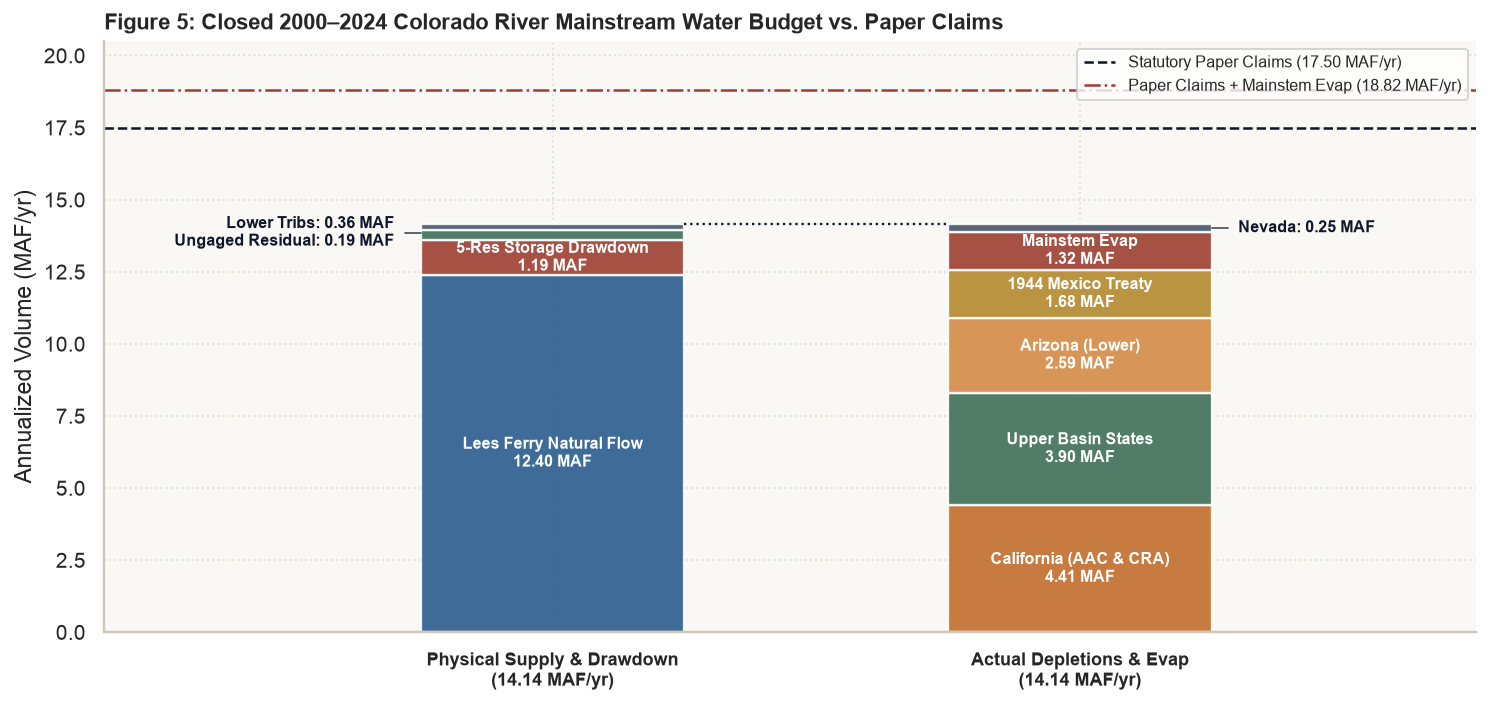

In [7]:
wb_meta = dict(q('SELECT meta_key, meta_value FROM water_budget_meta').values)
t0 = q('SELECT display_name, maf_yr FROM water_budget_nodes WHERE col_tier = 0 ORDER BY maf_yr DESC')
t3 = q('SELECT display_name, maf_yr, basin FROM water_budget_nodes WHERE col_tier = 3')

supply_parts = [
    ('Lees Ferry Natural Flow', float(t0.loc[t0['display_name'].str.contains('Lees Ferry'), 'maf_yr'].iloc[0]), PALETTE['blue']),
    ('5-Res Storage Drawdown', float(t0.loc[t0['display_name'].str.contains('Drawdown'), 'maf_yr'].iloc[0]), PALETTE['red']),
    ('Lower Mainstem Gaged Tribs', float(t0.loc[t0['display_name'].str.contains('Lower Mainstem'), 'maf_yr'].iloc[0]), PALETTE['sage']),
    ('Ungaged Inflows & Residual', float(t0.loc[t0['display_name'].str.contains('Residual'), 'maf_yr'].iloc[0]), PALETTE['slate']),
]
ub_states = float(t3.loc[t3['basin'] == 'upper', 'maf_yr'].sum())
depletion_parts = [
    ('California (AAC & CRA)', float(t3.loc[t3['display_name'] == 'California', 'maf_yr'].iloc[0]), PALETTE['ochre']),
    ('Upper Basin States', ub_states, PALETTE['sage']),
    ('Arizona (Lower)', float(t3.loc[t3['display_name'] == 'Arizona (Lower)', 'maf_yr'].iloc[0]), '#d48c46'),
    ('1944 Mexico Treaty', float(t3.loc[t3['display_name'] == 'Mexico', 'maf_yr'].iloc[0]), PALETTE['gold']),
    ('Mainstem Evap', float(t3.loc[t3['display_name'] == 'Mainstem Evap', 'maf_yr'].iloc[0]), PALETTE['red']),
    ('Nevada (SNWA)', float(t3.loc[t3['display_name'] == 'Nevada', 'maf_yr'].iloc[0]), PALETTE['slate']),
]

sup_sum = sum(v for _, v, _ in supply_parts)
dep_sum = sum(v for _, v, _ in depletion_parts)
assert abs(sup_sum - dep_sum) < 0.01, f'Mass balance mismatch: {sup_sum} vs {dep_sum}'
print(f'2000–2024 Supply Sum: {sup_sum:.4f} MAF/yr | Depletions Sum: {dep_sum:.4f} MAF/yr | Diff: {sup_sum - dep_sum:+.6f} MAF/yr')

fig, ax = plt.subplots(figsize=(10.8, 5.2), dpi=140)
bar_w = 0.50
for x_pos, parts in [(0, supply_parts), (1, depletion_parts)]:
    bottom = 0.0
    for label, val, col in parts:
        ax.bar(x_pos, val, width=bar_w, bottom=bottom, color=col, edgecolor='white', lw=1.2, alpha=0.90)
        if val >= 1.10:
            ax.text(x_pos, bottom + val / 2, f'{label}\n{val:.2f} MAF', ha='center', va='center',
                    color='white', fontsize=8.3, fontweight='bold')
        bottom += val

# Callout labels for thin top segments so no text overlaps
ax.text(-0.30, 13.86, 'Lower Tribs: 0.36 MAF\nUngaged Residual: 0.19 MAF',
        ha='right', va='center', fontsize=8.0, color=PALETTE['ink'], fontweight='bold')
ax.plot([-0.28, -0.25], [13.86, 13.86], color=PALETTE['slate'], lw=0.9)
ax.text(1.30, 14.02, 'Nevada: 0.25 MAF', ha='left', va='center', fontsize=8.2, color=PALETTE['ink'], fontweight='bold')
ax.plot([1.25, 1.28], [14.02, 14.02], color=PALETTE['slate'], lw=0.9)

ax.plot([bar_w/2, 1 - bar_w/2], [sup_sum, dep_sum], color=PALETTE['ink'], ls=':', lw=1.2)
ax.axhline(float(wb_meta['statutory_claims_maf']), color=PALETTE['ink'], ls='--', lw=1.3,
           label=f"Statutory Paper Claims ({float(wb_meta['statutory_claims_maf']):.2f} MAF/yr)")
ax.axhline(float(wb_meta['statutory_plus_evap_maf']), color=PALETTE['red'], ls='-.', lw=1.3,
           label=f"Paper Claims + Mainstem Evap ({float(wb_meta['statutory_plus_evap_maf']):.2f} MAF/yr)")
ax.set_xticks([0, 1])
ax.set_xticklabels([f'Physical Supply & Drawdown\n({sup_sum:.2f} MAF/yr)', f'Actual Depletions & Evap\n({dep_sum:.2f} MAF/yr)'], fontsize=9.5, fontweight='bold')
ax.set_xlim(-0.85, 1.75)
ax.set_ylim(0, 20.5)
ax.set_ylabel('Annualized Volume (MAF/yr)')
ax.set_title('Figure 5: Closed 2000–2024 Colorado River Mainstream Water Budget vs. Paper Claims', fontsize=11.2, fontweight='bold', loc='left')
ax.legend(loc='upper right', fontsize=8.2, frameon=True, facecolor='white')
sns.despine(ax=ax)
plt.tight_layout()
plt.show()
conn.close()


## 7. Known Limitations & AI Collaboration Disclosure
- **Temporal & Accounting Boundaries:** Operational streamgages report instantaneous rate (`cfs`), whereas the macro budget reports 25-year annualized volume (`MAF/yr`, `2000–2024`). Off-mainstem Gila Basin consumptive use (`1.99 MAF/yr`) is excluded from mainstream Compact totals under *Arizona v. California* (1963).
- **Bathymetric Sedimentation:** Reservoir storage series use official USBR elevation–capacity tables; gradual deltaic sedimentation slightly reduces physical volume between bathymetric surveys.
- **Academic AI Transparency:** All AI pair-programming sessions, model selections, verification scripts, and prompt transcripts are documented in [`AI_LOG.md`](../AI_LOG.md), [`CHANGELOG.md`](../CHANGELOG.md), and [`web/ai_complete_prompt_archive.html`](../web/ai_complete_prompt_archive.html).
